# 模块顺序

- **①** agent/replay_buffer.py  ← 最简单，35行，理解"经验回放"
- **②** agent/dqn.py            ← 核心算法，158行
- **③** env/movie_env.py        ← 环境模拟器，150行
- **④** train_cartpole.py       ← 最简单的训练脚本（验证 DQN 是否写对）
- **⑤** train_recommend.py      ← 推荐任务的训练（参数更多）
- **⑥** eval.py                 ← 策略对比评估
- **⑦** app.py                  ← Gradio 可视化界面（最外围）

# 模块工作流

整体数据流：

MovieLens 数据集
      ↓
env/movie_env.py（用户模拟器）
  - 把静态评分数据 → 变成可以 reset/step 的交互环境
  - 用 SVD 分解学习用户/电影的隐向量
  - 每步随机抽 20 部候选电影
      ↓
agent/dqn.py（DQN 智能体）
  - QNetwork：普通 MLP（给 CartPole 用）
  - CandidateQNetwork：逐候选打分结构（给推荐用，核心创新点）
  - act()：ε-greedy 选动作
  - update()：从经验回放池采样，计算 TD 损失，反向传播
      ↓
agent/replay_buffer.py（经验回放池）
  - 存储 (s, a, r, s', done) 转移样本
  - 随机打乱采样，打破时间相关性
      ↓
train_*.py（训练循环）
  - 不断交互 → 存经验 → 更新网络 → 同步目标网络

# 较难理解的部分

In [ ]:
# env/movie_env.py 第40行
#state_dim = 2*k + n_candidates*(k+1)
#         = 2×20 + 20×(20+1) = 40 + 420 = 460

- 前 40 维 = 用户偏好向量(20) + 历史电影 embedding 均值(20)
- 后 420 维 = 20 部候选电影各自的特征（隐向量20维 + 物品偏差1维）
- 候选特征必须放进状态，否则动作编号毫无意义

## 目标函数
> 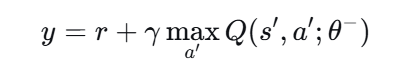
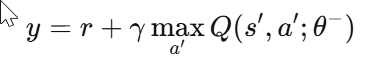

## 损失函数

> 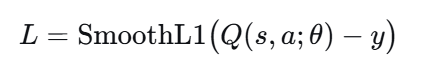
> 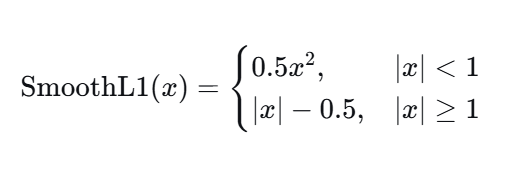

# 为什么用到贪婪函数

**探索 vs 利用** :
- 探索（Exploration）：尝试新动作，发现可能更好的选择
- 利用（Exploitation）：选当前已知最优动作，获取最大奖励
> - 纯贪婪（永远选 Q 值最大的动作）的问题： → 智能体可能陷入局部最优，错过了真正更好的动作
> - 纯随机（完全随机选动作）的问题： → 学到的知识完全没用上，奖励很低

### 项目中的 ε-greedy 策略

**每次选动作时掷骰子：**
- 掷出 < ε  → 随机选（探索）
- 掷出 ≥ ε  → 选 Q 值最大的（贪婪利用）

# Summary

**贪婪 = 选 Q 值最大的动作 = 利用当前学到的知识**
> DDQN https://www.bilibili.com/video/BV1aGBLYeExG/?spm_id_from=333.788.videopod.episodes&vd_source=cb0adfbed63dfe6dc7e54a8665f71321&p=12-